# High Accuracy, Low Assurance
## Outcome-proxy sensitivity, geographic transportability, fairness, and uncertainty in student-depression prediction

This notebook is the executable companion to the manuscript. It evaluates a public survey dataset of 4,464 students using leakage-safe nested cross-validation, leave-one-division-out validation, subgroup audits, and split-conformal prediction.

**Interpretation boundary.** The public data card describes a binary `Depression` field but does not document a validated diagnostic instrument or clinician assessment. We therefore analyze a **self-reported depression indicator**, not a clinical diagnosis. `Health_condition` is treated as a potential outcome proxy because its temporal relationship and questionnaire wording are undocumented.

Dataset: Haque and Alom, *Student Depression Detection Dataset*, Version 2, CC BY 4.0, DOI: [10.17632/xn9cb5zpgg.2](https://doi.org/10.17632/xn9cb5zpgg.2).

## Study design

1. Audit missingness, duplicates, prevalence, and conditional outcome rates.
2. Compare a **full** setting with a **proxy-free** setting that excludes `Health_condition`.
3. Use 5-fold outer cross-validation; tune hyperparameters only inside each training fold using 3-fold inner cross-validation and AUPRC.
4. Select one model per setting by pooled out-of-fold AUPRC.
5. Hold out each home division in turn to approximate geographic transportability.
6. Report gender, family-background, and division subgroup errors without claiming that observational parity proves fairness.
7. Evaluate 90% split-conformal prediction over five independent splits.

The primary metric is AUPRC because only 26.9% of records are positive. AUROC, Brier score, sensitivity, specificity, F1, and balanced accuracy are secondary metrics.

In [1]:
from pathlib import Path
import json
import platform

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import Image, display

from research_pipeline import run_all

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.6
pandas: 3.0.5
scikit-learn: 1.9.0


## Execute the complete reproducible pipeline

In [2]:
results = run_all(
    csv_path=Path("Student_Depression_Dataset.csv"),
    artifact_root=Path("artifacts"),
)
print("Selected models:", results["selected"])

Nested CV: full / Dummy


Nested CV: full / Logistic


Nested CV: full / RandomForest


Nested CV: full / ExtraTrees


Nested CV: full / HistGradientBoosting


Nested CV: proxy_free / Dummy


... (3 outputs left out)

Nested CV: proxy_free / HistGradientBoosting


Geographic validation: full / RandomForest


Geographic validation: proxy_free / HistGradientBoosting


Selected models: {'full': 'RandomForest', 'proxy_free': 'HistGradientBoosting'}


## Dataset and potential outcome-proxy audit

,item,value
0,Rows,4464.000000
1,Predictors,12.000000
2,Depression positive,1201.000000
3,Depression prevalence,0.269041
4,Missing cells,0.000000
5,Duplicate rows,0.000000


,Health_condition,count,depressed_n,depression_rate
0,Critical,634,634,1.000
1,Abnormal,881,484,0.549
2,Normal,1787,83,0.046
3,Good,1162,0,0.000


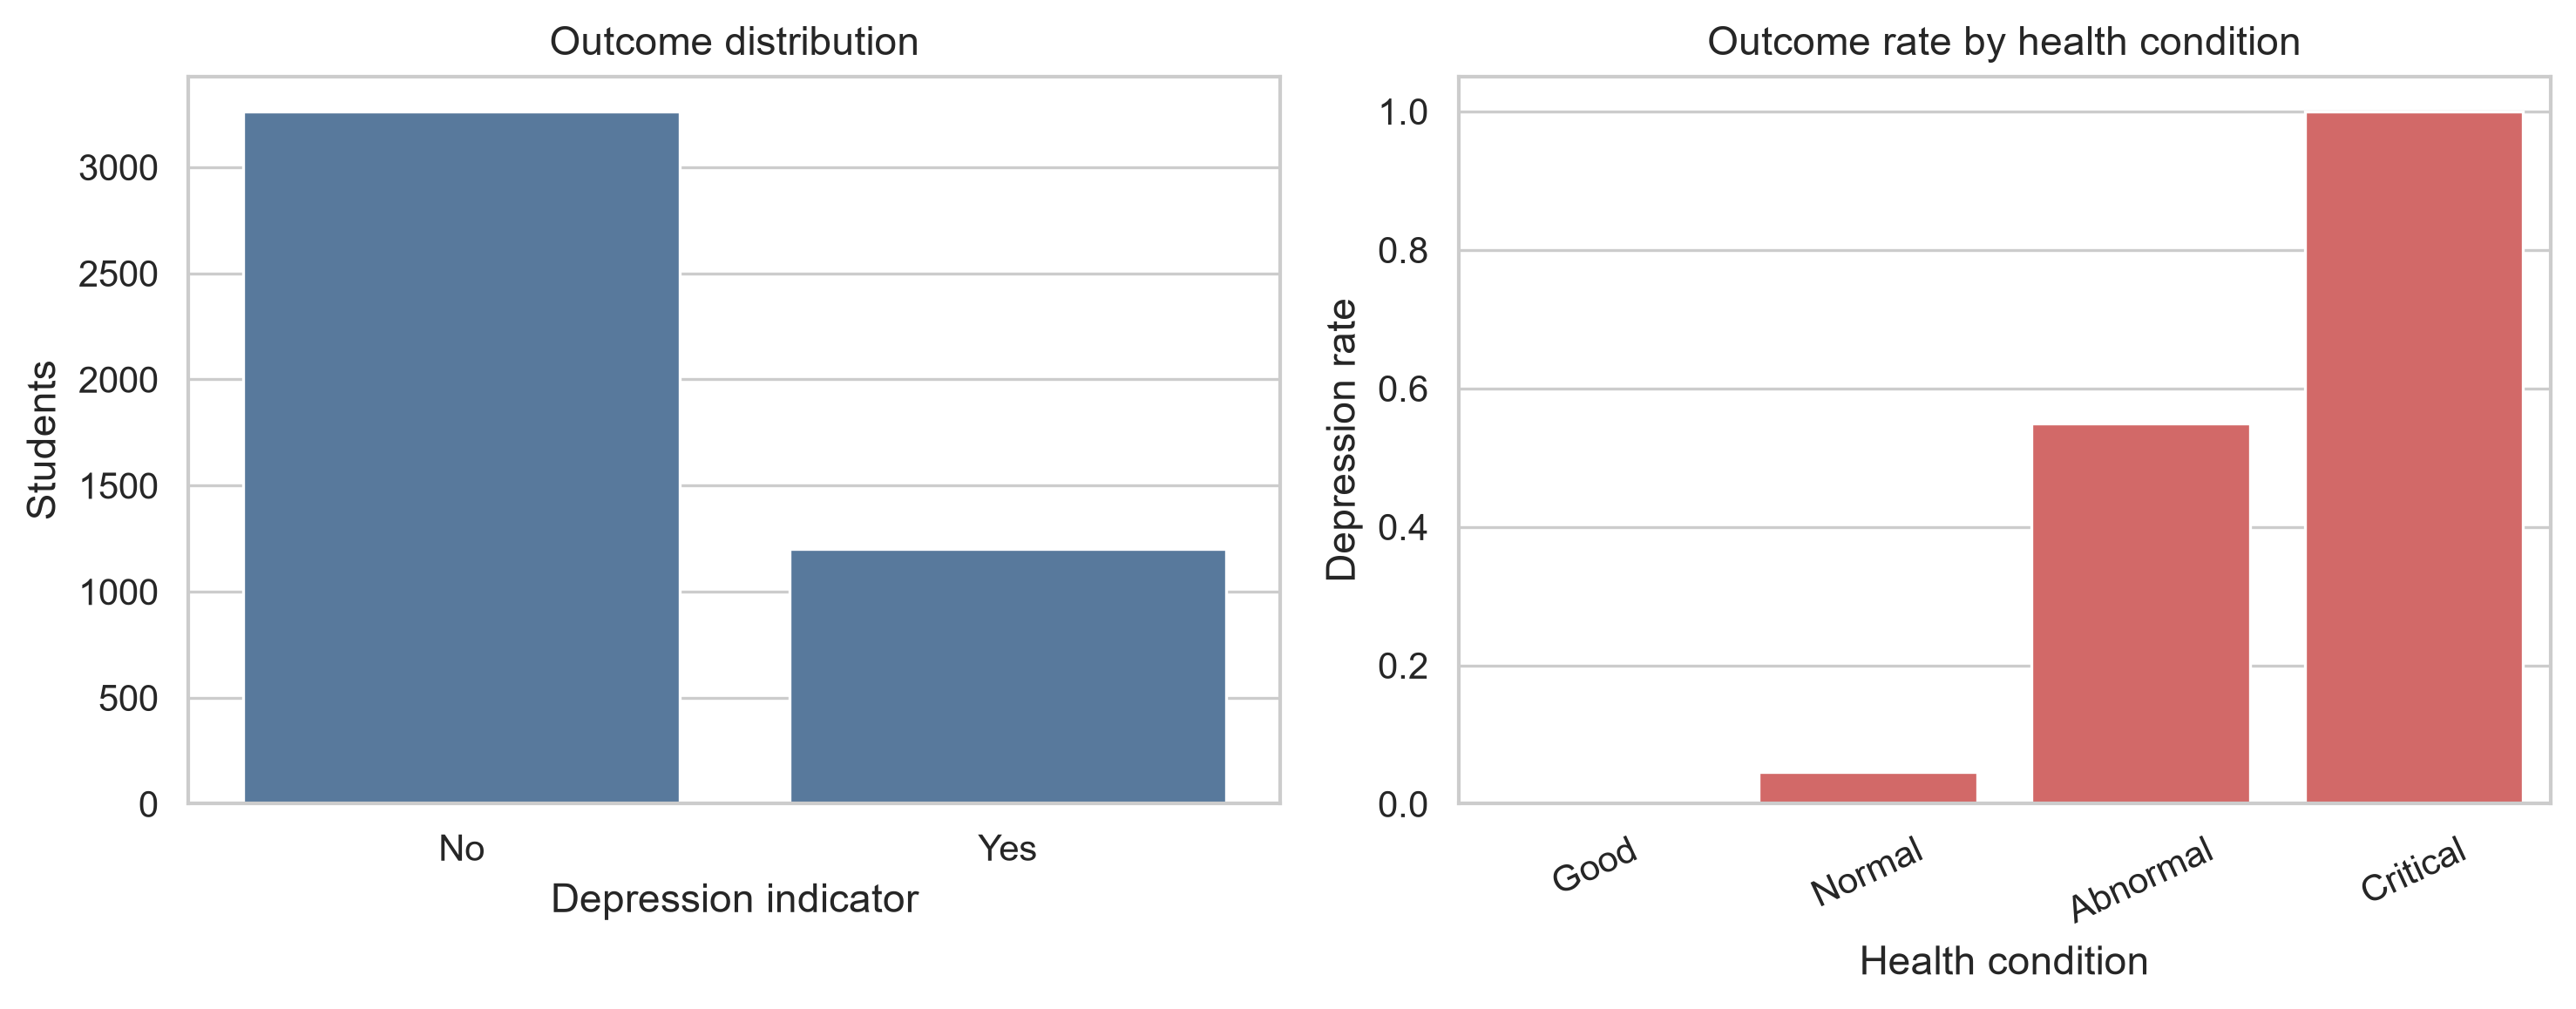

In [3]:
display(results["audit"]["audit"])
display(results["audit"]["health"].style.format({"depression_rate": "{:.3f}"}))
display(Image(filename="artifacts/figures/figure_1_data_and_proxy_audit.png", width=900))

`Critical` health status perfectly co-occurs with a positive outcome, while `Good` health status perfectly co-occurs with a negative outcome. This does not by itself prove data leakage; it demonstrates severe construct overlap or outcome-proxy risk that must be stress-tested.

## Nested cross-validated model performance

,feature_set,model,AUROC,AUROC_low,AUROC_high,AUPRC,AUPRC_low,AUPRC_high,Brier,Balanced_accuracy,Sensitivity,Specificity,F1
2,full,RandomForest,0.999,0.999,1.000,0.998,0.997,0.999,0.010,0.979,0.959,0.999,0.978
4,full,HistGradientBoosting,0.999,0.997,1.000,0.998,0.996,0.999,0.005,0.990,0.982,0.998,0.988
3,full,ExtraTrees,0.999,0.998,0.999,0.997,0.995,0.998,0.011,0.975,0.953,0.998,0.973
1,full,Logistic,0.992,0.988,0.995,0.988,0.984,0.992,0.018,0.965,0.940,0.990,0.956
0,full,Dummy,0.499,0.482,0.516,0.269,0.253,0.285,0.197,0.500,0.000,1.000,0.000
9,proxy_free,HistGradientBoosting,0.751,0.735,0.766,0.520,0.491,0.551,0.167,0.612,0.312,0.911,0.402
7,proxy_free,RandomForest,0.756,0.739,0.771,0.510,0.480,0.541,0.166,0.576,0.201,0.951,0.301
8,proxy_free,ExtraTrees,0.738,0.721,0.752,0.464,0.435,0.494,0.171,0.559,0.172,0.946,0.262
6,proxy_free,Logistic,0.718,0.701,0.733,0.454,0.425,0.485,0.174,0.555,0.154,0.956,0.242
5,proxy_free,Dummy,0.499,0.482,0.516,0.269,0.253,0.285,0.197,0.500,0.000,1.000,0.000


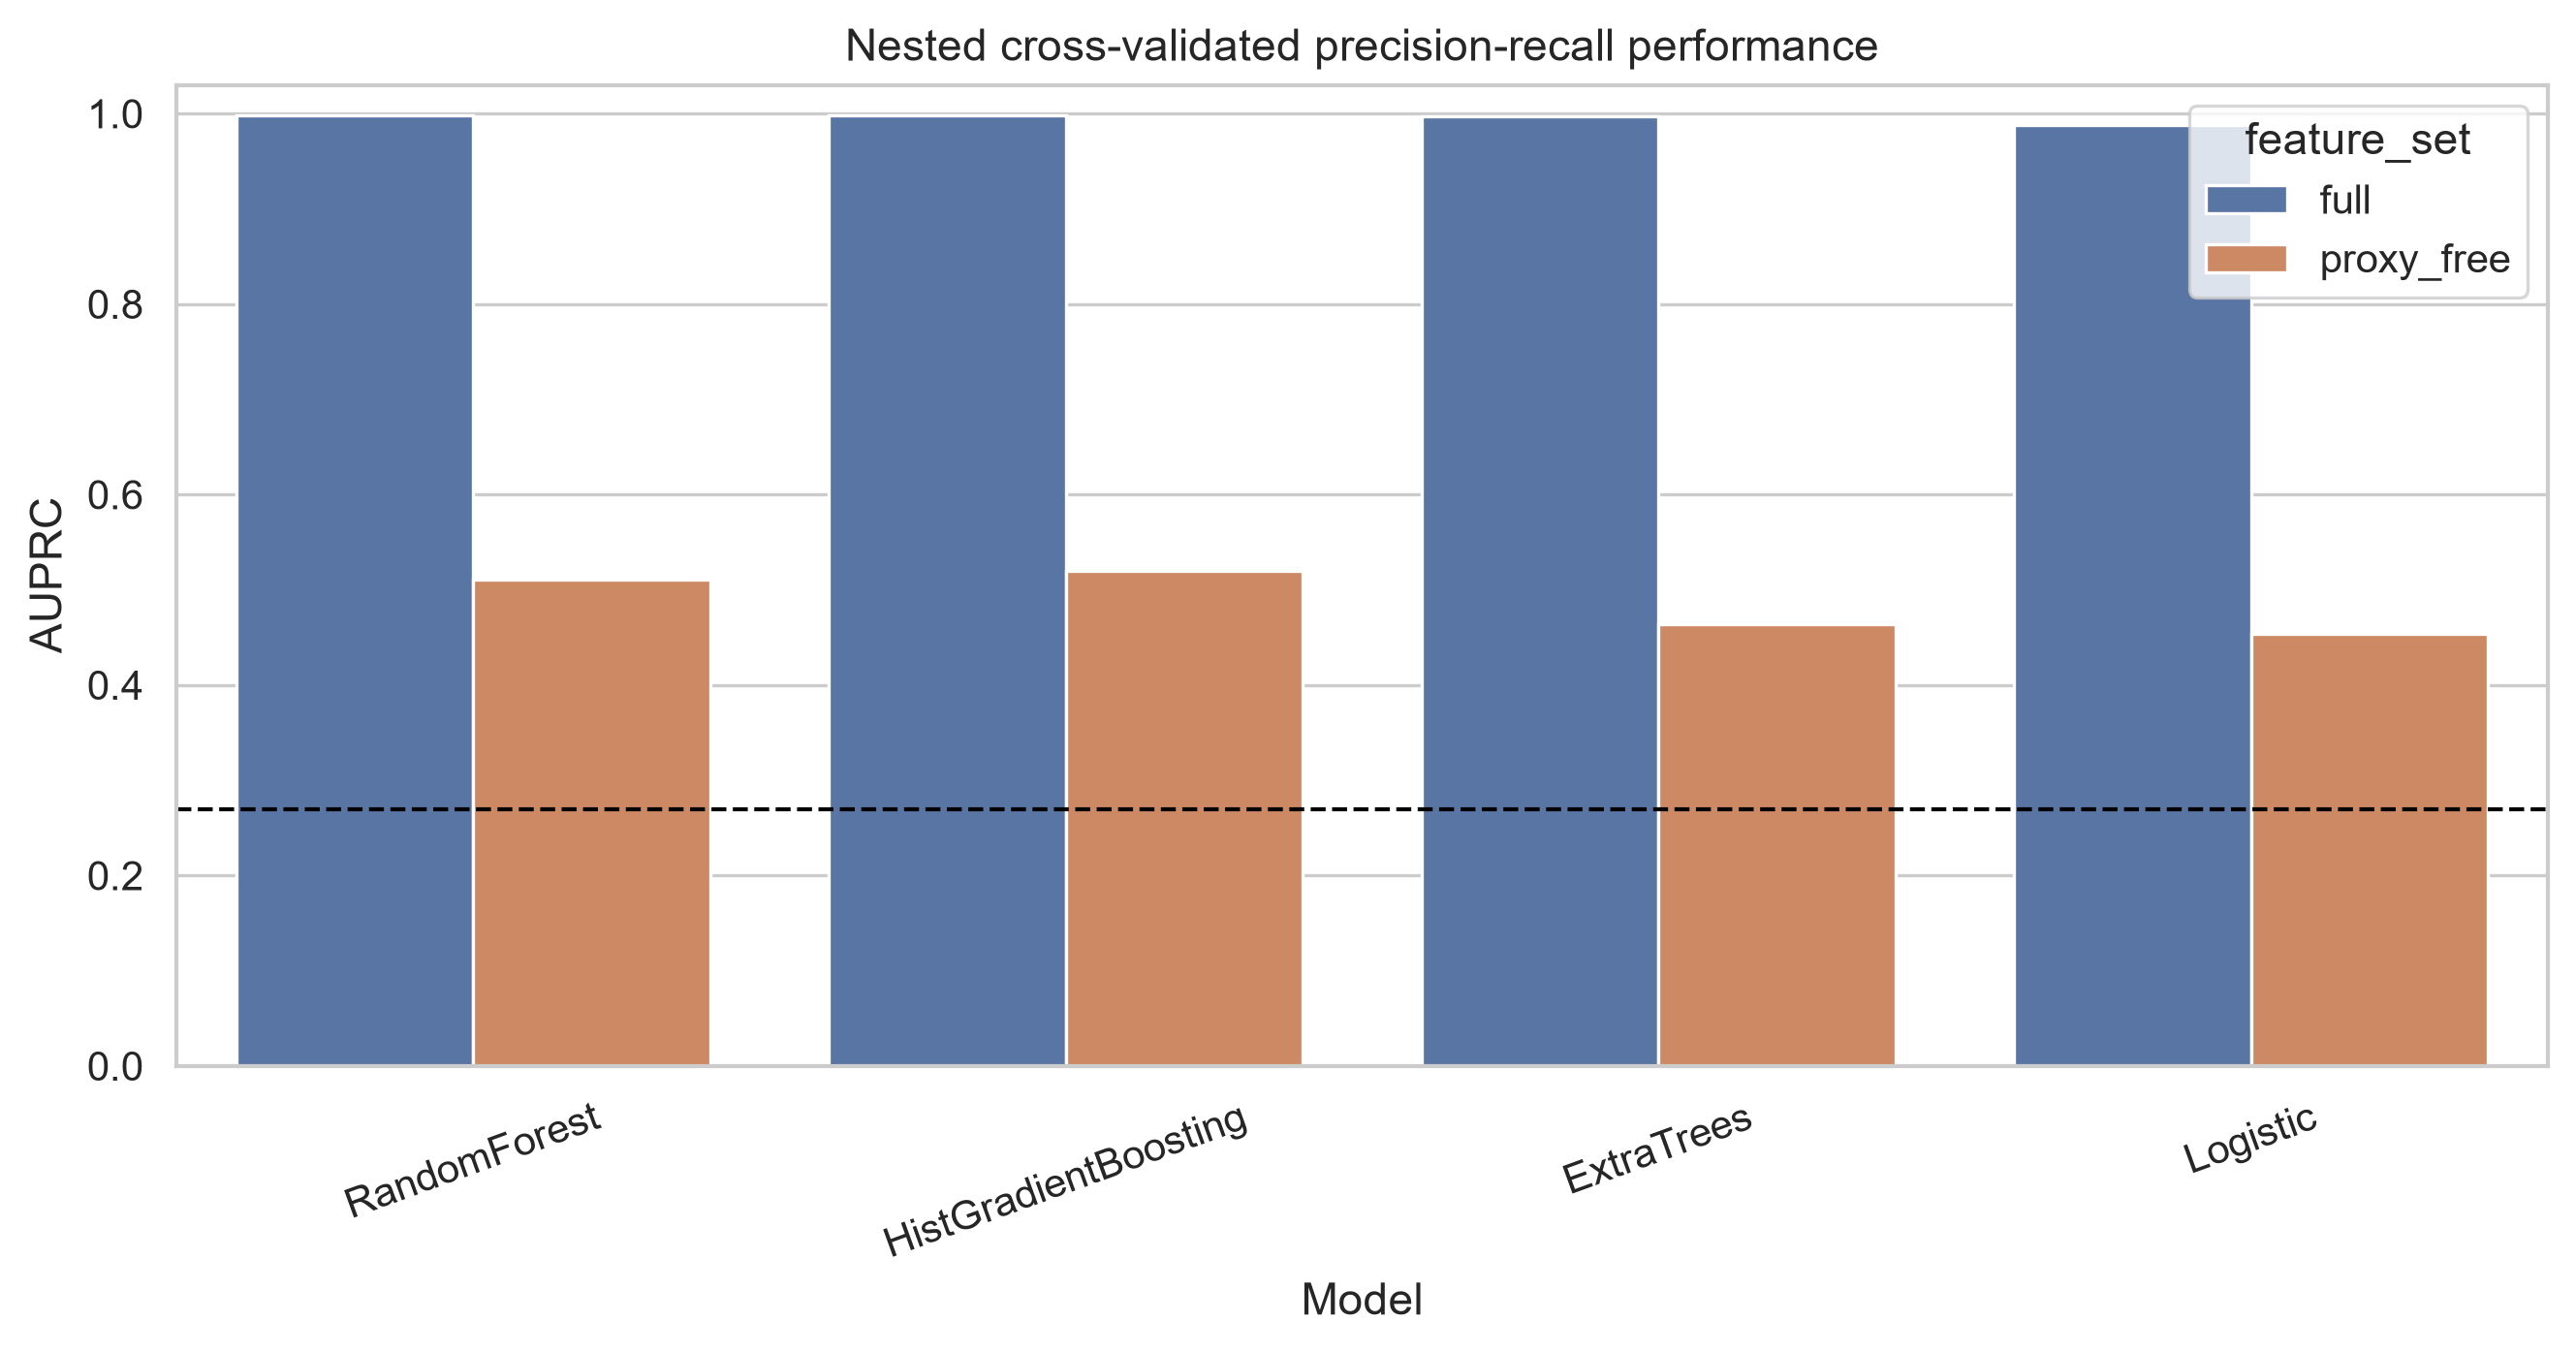

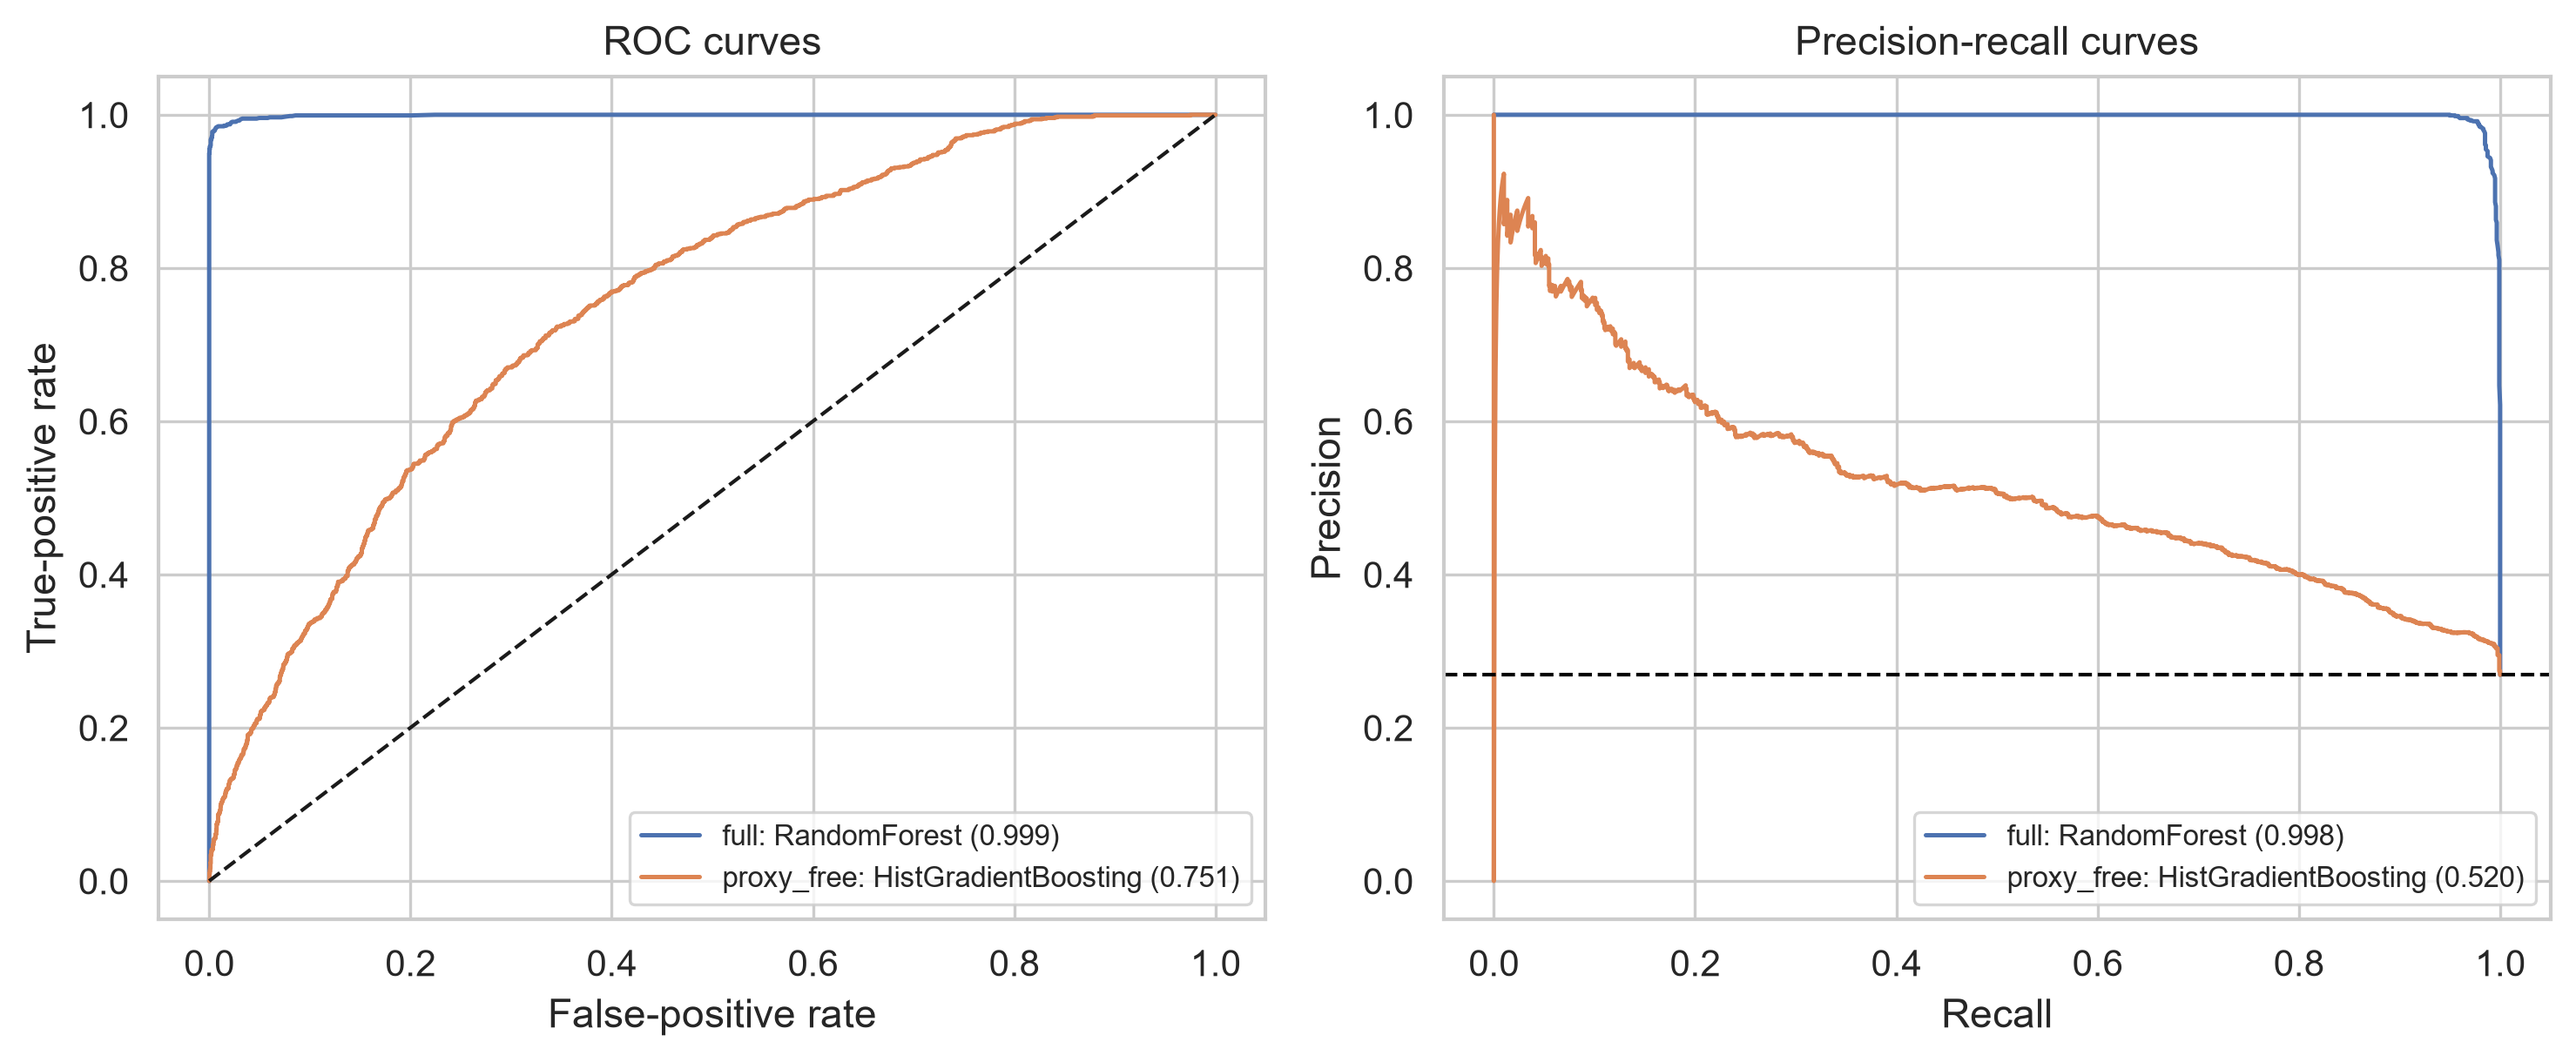

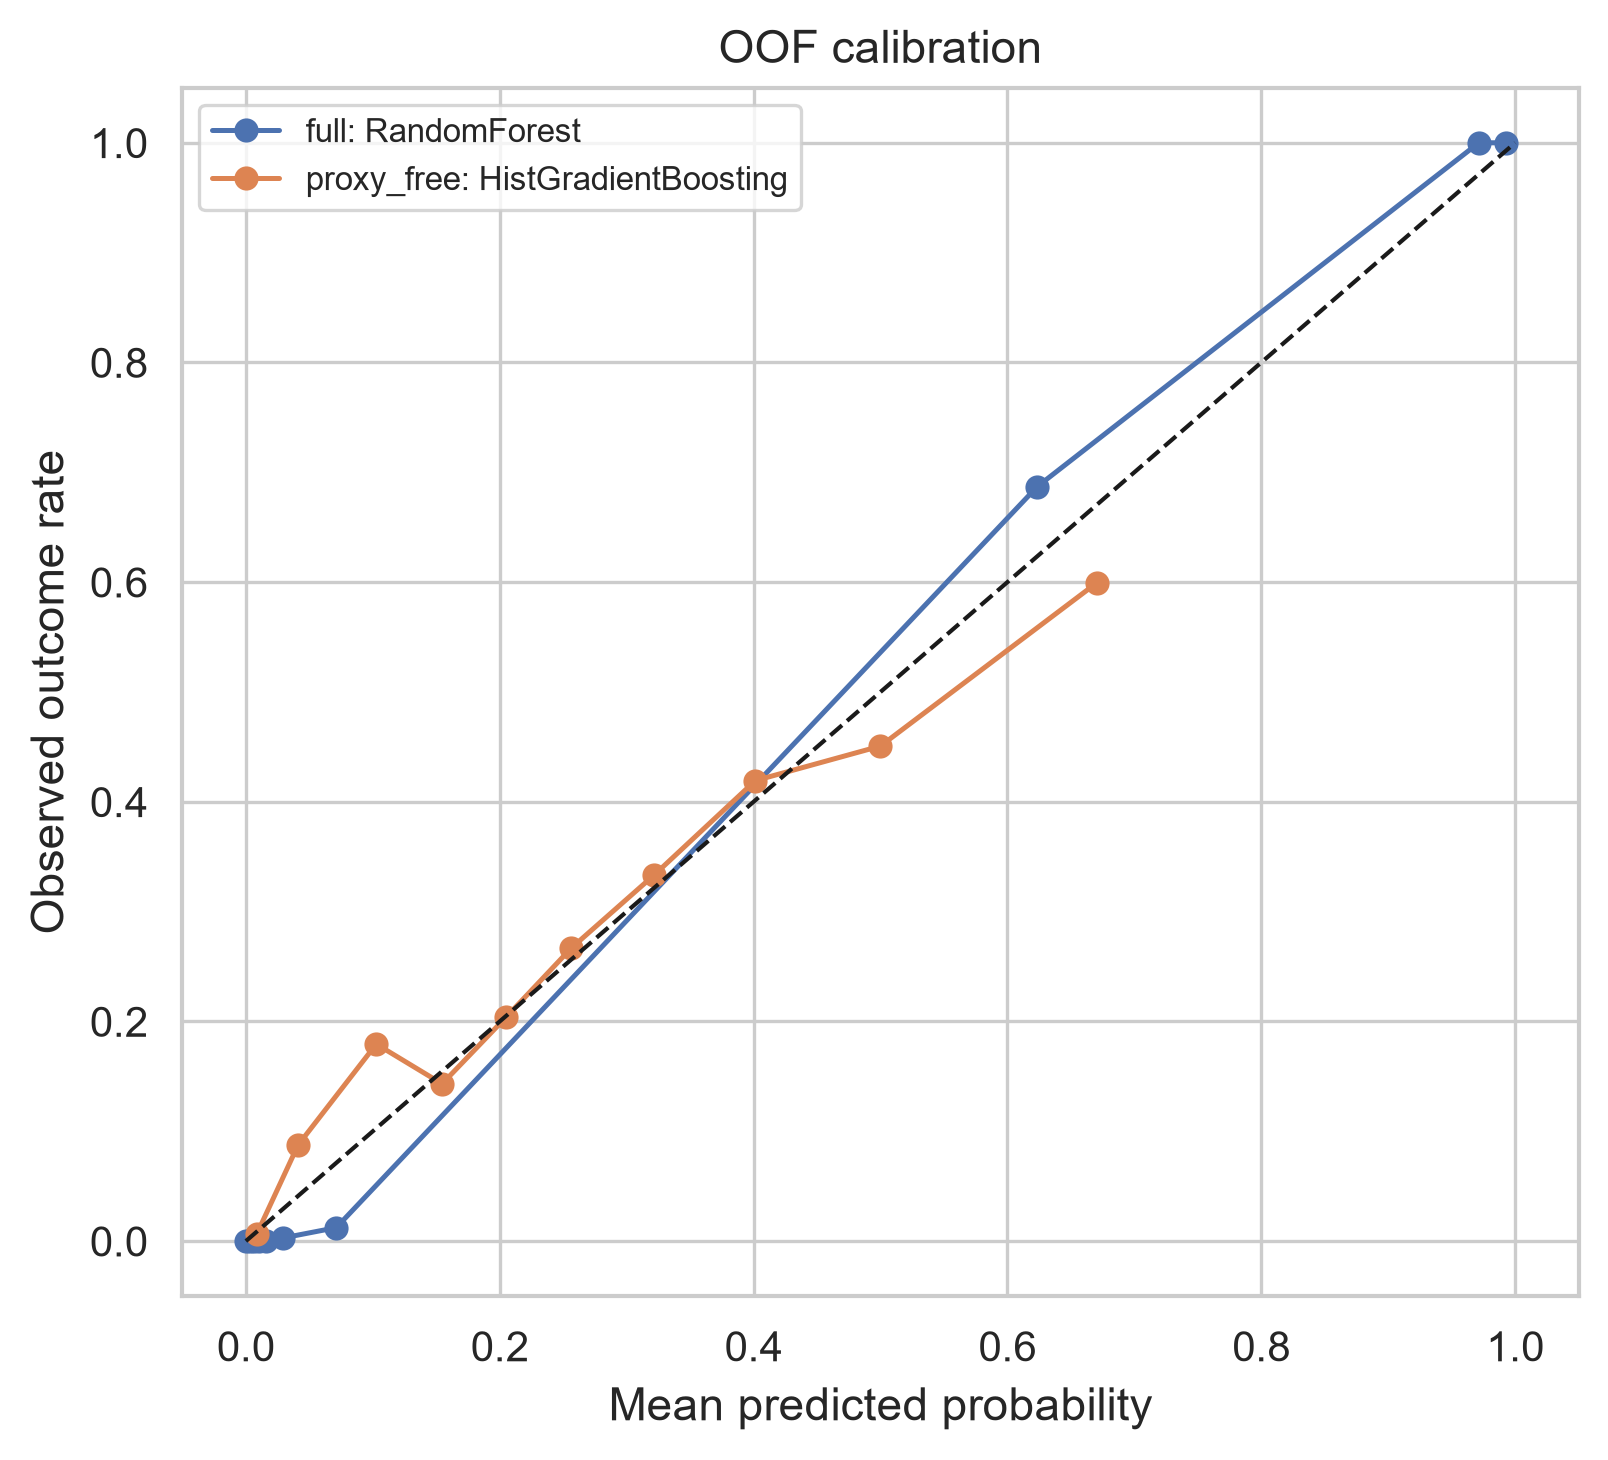

In [4]:
performance_columns = [
    "feature_set", "model", "AUROC", "AUROC_low", "AUROC_high",
    "AUPRC", "AUPRC_low", "AUPRC_high", "Brier",
    "Balanced_accuracy", "Sensitivity", "Specificity", "F1"
]
display(
    results["summary"][performance_columns]
    .sort_values(["feature_set", "AUPRC"], ascending=[True, False])
    .style.format(precision=3)
)
display(Image(filename="artifacts/figures/figure_2_nested_cv_auprc.png", width=900))
display(Image(filename="artifacts/figures/figure_3_discrimination_curves.png", width=900))
display(Image(filename="artifacts/figures/figure_4_calibration.png", width=550))

Model selection uses AUPRC, not accuracy. The full model and proxy-free model answer different questions: the former estimates performance when all recorded variables are available; the latter estimates robustness to removing the strongest potential outcome proxy.

## Leave-one-division-out geographic validation

,feature_set,model,held_out_division,n,prevalence,AUROC,AUPRC,Brier,Balanced_accuracy,F1,Sensitivity,Specificity,FNR,FPR
0,full,RandomForest,Overall,4464,0.269,0.999,0.998,0.010,0.978,0.977,0.958,0.999,0.042,0.001
1,proxy_free,HistGradientBoosting,Overall,4464,0.269,0.691,0.452,0.184,0.586,0.362,0.296,0.876,0.704,0.124


,feature_set,model,held_out_division,n,prevalence,AUROC,AUPRC,Brier,Sensitivity,Specificity
0,full,RandomForest,Barisal,355,0.276,0.998,0.997,0.007,0.980,1.000
1,full,RandomForest,Chittagong,400,0.305,0.999,0.999,0.010,0.967,0.996
2,full,RandomForest,Dhaka,1527,0.224,0.999,0.997,0.012,0.953,1.000
3,full,RandomForest,Khulna,548,0.310,1.000,1.000,0.006,0.976,1.000
4,full,RandomForest,Mymensingh,338,0.278,1.000,0.999,0.010,0.947,1.000
5,full,RandomForest,Rajshahi,488,0.316,1.000,0.999,0.010,0.961,1.000
6,full,RandomForest,Rangpur,363,0.320,1.000,0.999,0.009,0.966,1.000
7,full,RandomForest,Sylhet,445,0.236,0.999,0.996,0.015,0.905,0.997
8,proxy_free,HistGradientBoosting,Barisal,355,0.276,0.700,0.505,0.178,0.255,0.934
9,proxy_free,HistGradientBoosting,Chittagong,400,0.305,0.732,0.541,0.186,0.311,0.910


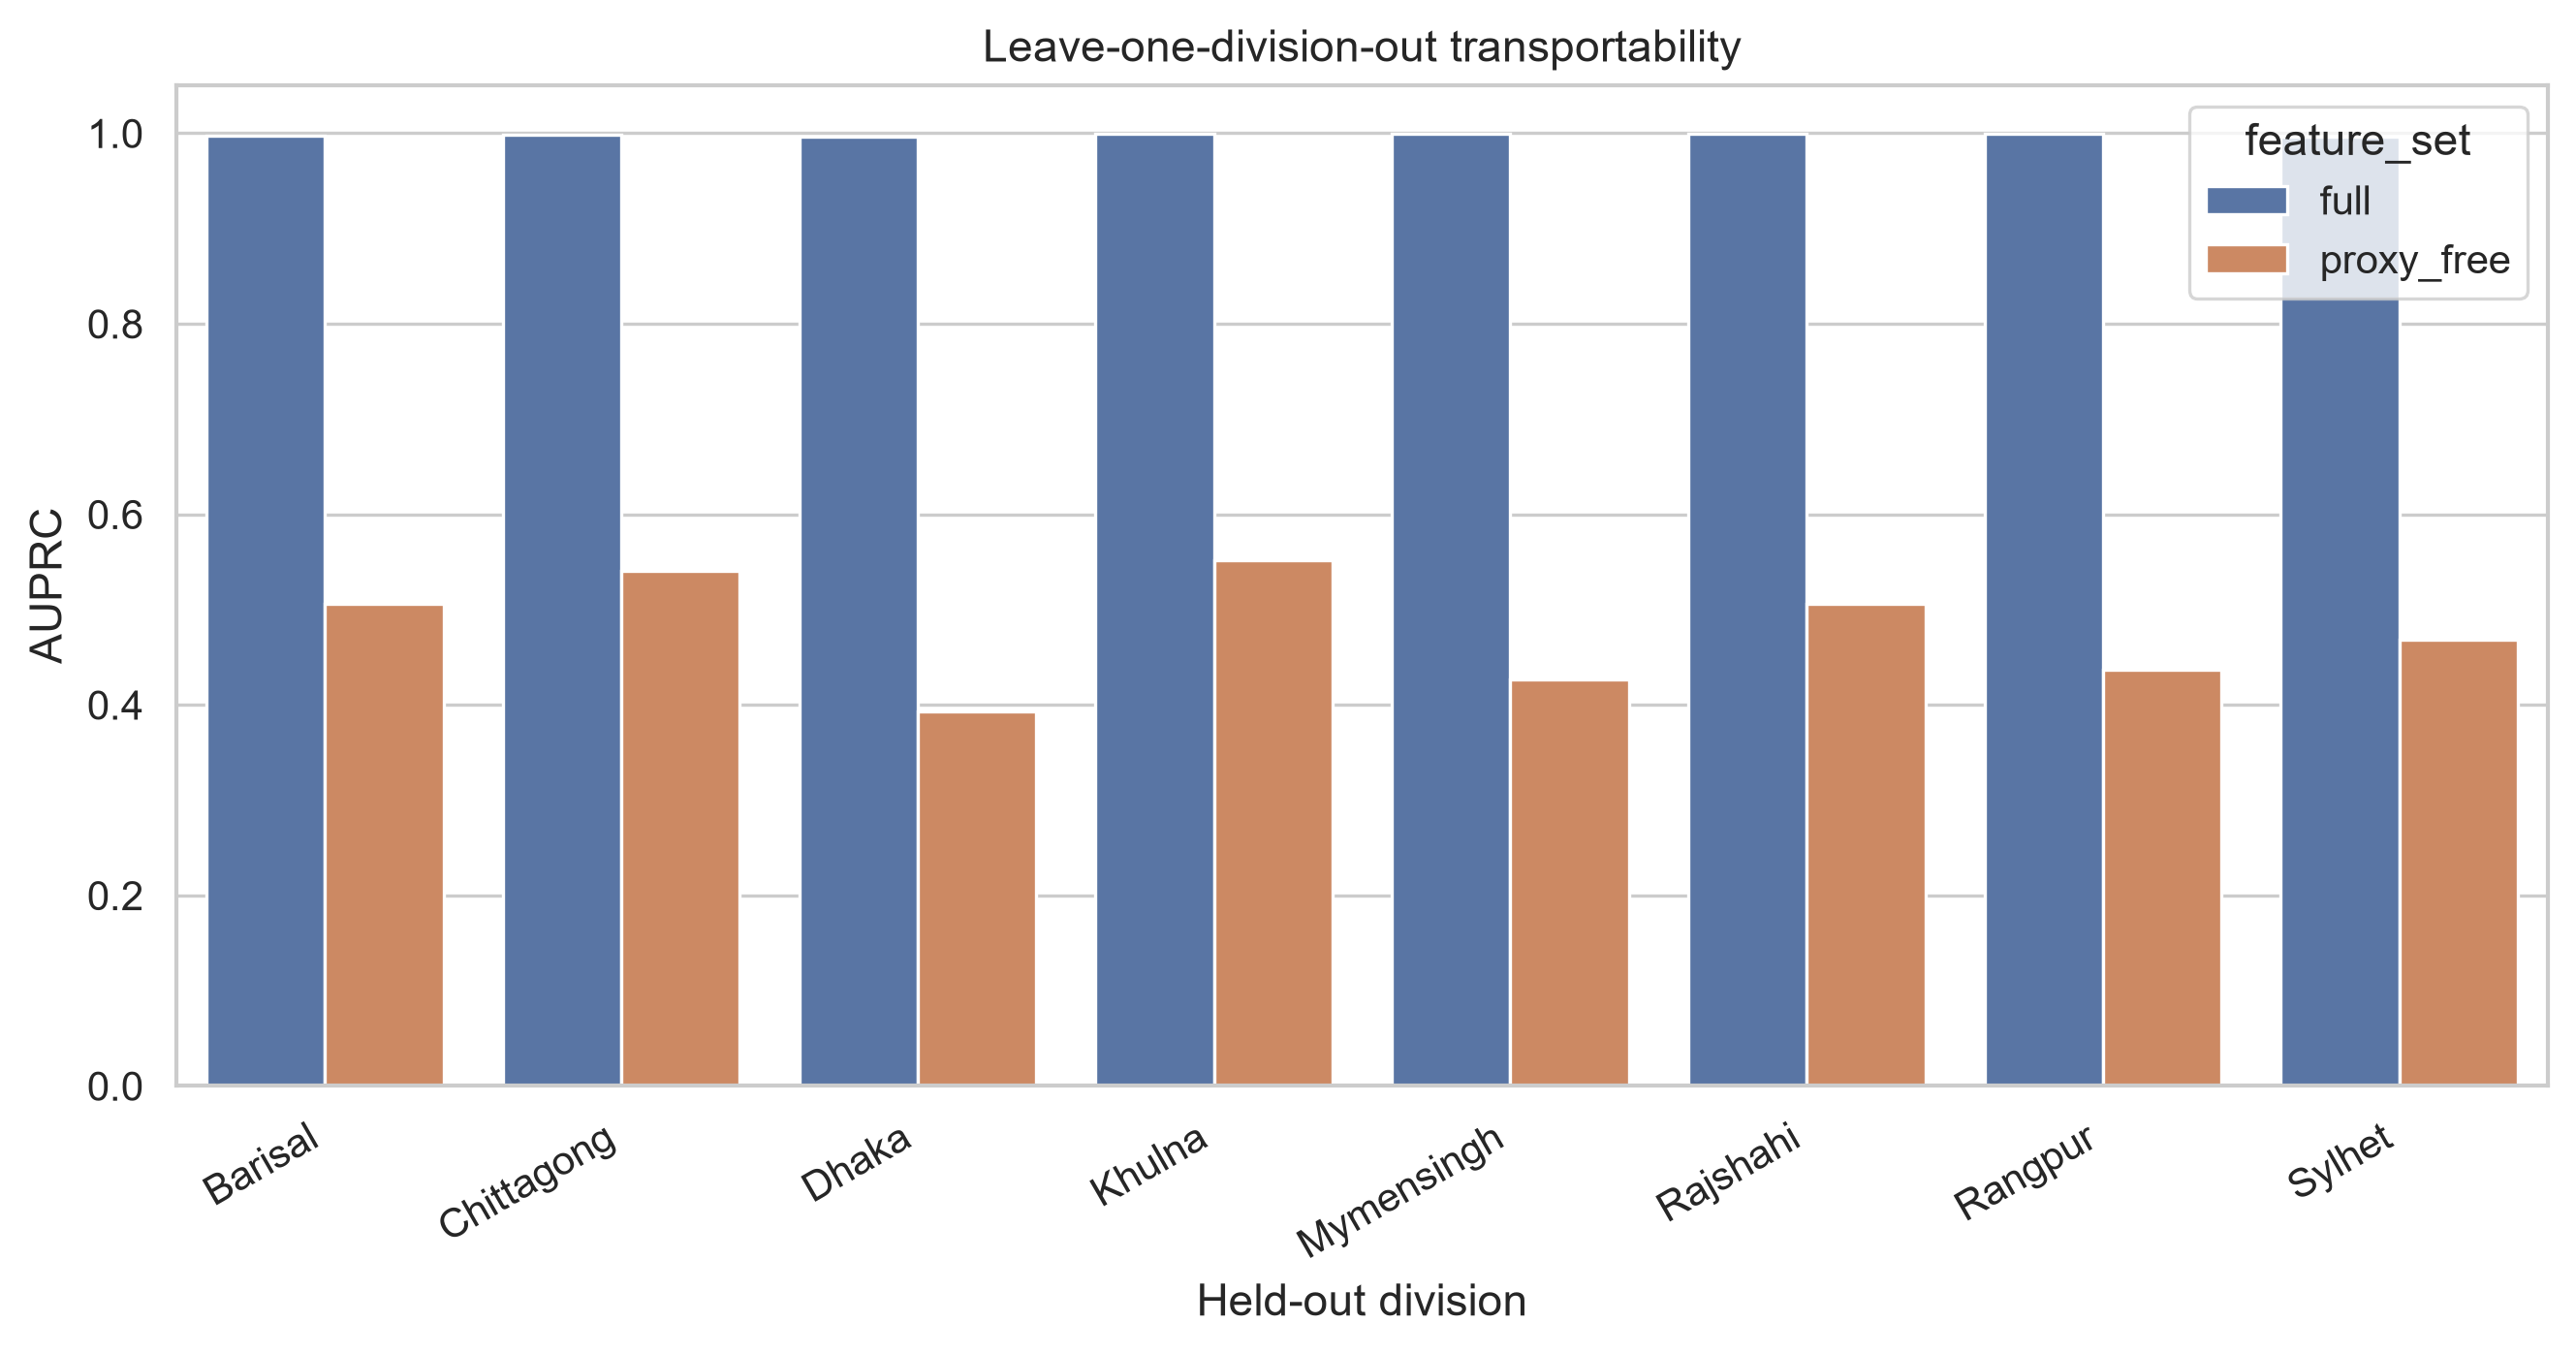

In [5]:
display(results["geo_overall"].style.format(precision=3))
display(
    results["geo_detail"][[
        "feature_set", "model", "held_out_division", "n", "prevalence",
        "AUROC", "AUPRC", "Brier", "Sensitivity", "Specificity"
    ]].style.format(precision=3)
)
display(Image(filename="artifacts/figures/figure_5_geographic_transportability.png", width=900))

## Subgroup performance audit

In [6]:
gaps = pd.read_csv("artifacts/tables/subgroup_metric_gaps.csv")
display(gaps.style.format(precision=3))

gender_rows = results["fairness"][results["fairness"]["group"] == "Gender"]
display(gender_rows.style.format(precision=3))

,feature_set,model,group,FNR_gap,FPR_gap,Brier_gap
0,full,RandomForest,Family_background,0.068,0.001,0.008
1,full,RandomForest,Gender,0.001,0.002,0.000
2,full,RandomForest,Home_division,0.059,0.004,0.005
3,proxy_free,HistGradientBoosting,Family_background,0.188,0.070,0.047
4,proxy_free,HistGradientBoosting,Gender,0.008,0.022,0.001
5,proxy_free,HistGradientBoosting,Home_division,0.284,0.082,0.049


,feature_set,model,group,level,n,prevalence,AUROC,AUPRC,Brier,Balanced_accuracy,F1,Sensitivity,Specificity,FNR,FPR
0,full,RandomForest,Gender,Female,2462,0.266,0.999,0.998,0.009,0.979,0.978,0.959,0.999,0.041,0.001
1,full,RandomForest,Gender,Male,2002,0.273,0.999,0.998,0.010,0.979,0.977,0.960,0.998,0.040,0.002
13,proxy_free,HistGradientBoosting,Gender,Female,2462,0.266,0.741,0.526,0.167,0.615,0.404,0.308,0.921,0.692,0.079
14,proxy_free,HistGradientBoosting,Gender,Male,2002,0.273,0.762,0.515,0.166,0.608,0.400,0.317,0.899,0.683,0.101


These are descriptive subgroup audits. They do not establish individual fairness, causal fairness, or clinical safety. Differences can reflect sample size, outcome prevalence, measurement differences, or model behavior.

## Uncertainty and selective prediction

,seed,alpha,qhat,n_test,coverage,mean_set_size,singleton_rate,empty_rate,singleton_accuracy,AUROC,AUPRC
0,42,0.100,0.728,893,0.907,1.411,0.589,0.000,0.842,0.744,0.485
1,43,0.100,0.772,893,0.907,1.440,0.560,0.000,0.834,0.736,0.493
2,44,0.100,0.708,893,0.910,1.394,0.606,0.000,0.852,0.753,0.523
3,45,0.100,0.698,893,0.887,1.343,0.657,0.000,0.828,0.748,0.478
4,46,0.100,0.709,893,0.905,1.366,0.634,0.000,0.850,0.758,0.525


,seed,alpha,qhat,n_test,coverage,mean_set_size,singleton_rate,empty_rate,singleton_accuracy,AUROC,AUPRC
mean,44.000,0.100,0.723,893.000,0.903,1.391,0.609,0.000,0.841,0.748,0.501


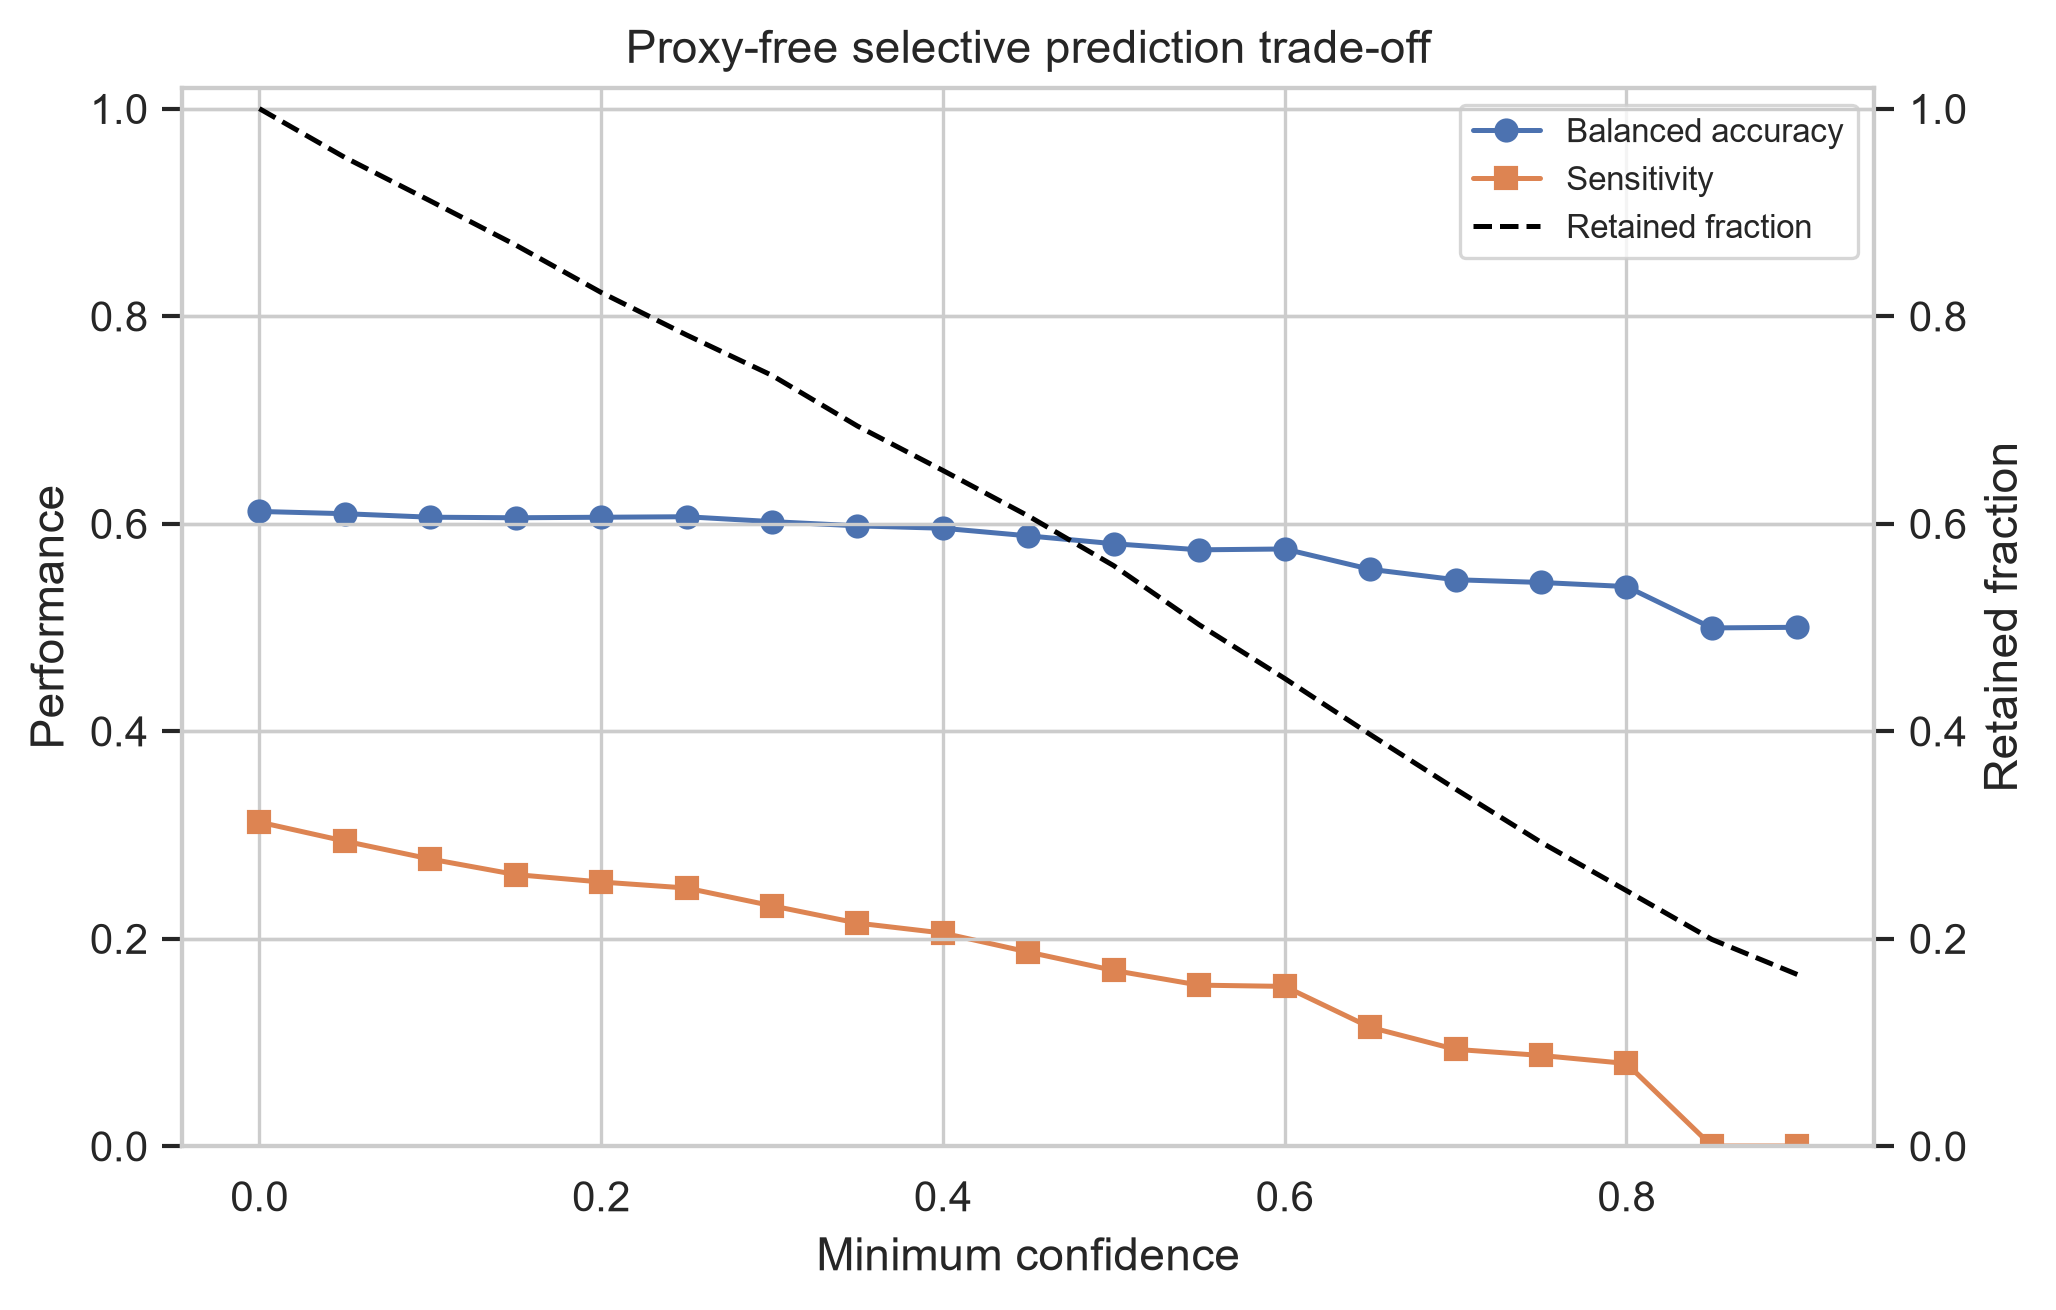

In [7]:
display(results["conformal_runs"].style.format(precision=3))
display(results["conformal_runs"].mean(numeric_only=True).to_frame("mean").T.style.format(precision=3))
display(Image(filename="artifacts/figures/figure_6_selective_prediction.png", width=750))

At nominal 90% coverage, split-conformal prediction is evaluated over five independent data splits. Coverage is marginal under exchangeability; it is not guaranteed for every subgroup or after deployment shift. Non-singleton prediction sets should be interpreted as cases requiring further assessment, not automated decisions.

## Reproducibility checks

In [8]:
required_files = [
    "artifacts/results/run_manifest.json",
    "artifacts/results/oof_predictions.csv",
    "artifacts/tables/nested_cv_performance.csv",
    "artifacts/tables/geographic_validation_overall.csv",
    "artifacts/tables/subgroup_fairness_metrics.csv",
    "artifacts/tables/conformal_runs.csv",
]
for filename in required_files:
    path = Path(filename)
    assert path.exists() and path.stat().st_size > 0, filename

assert len(results["raw"]) == 4464
assert int(results["y"].sum()) == 1201
assert results["predictions"].groupby(["feature_set", "model"]).size().eq(4464).all()
assert results["predictions"]["probability"].between(0, 1).all()
assert set(results["selected"]) == {"full", "proxy_free"}

with open("artifacts/results/run_manifest.json", encoding="utf-8") as handle:
    manifest = json.load(handle)
display(manifest["selected_models"])
print("All reproducibility checks passed.")

{'full': 'RandomForest', 'proxy_free': 'HistGradientBoosting'}

All reproducibility checks passed.


## Conclusions

The near-perfect full-model result is not sufficient evidence of deployable depression screening. Performance falls sharply when `Health_condition` is removed and falls further under division-held-out testing. The defensible contribution is therefore an outcome-proxy sensitivity and transportability audit, not a claim of clinical diagnosis.

External validation using a documented instrument such as PHQ-9 or CES-D is required before clinical or institutional use. No result in this notebook should be used to diagnose, rank, or discipline students.